# Human Activity Recognition Using Deep Learning

## A Comparative Study of Single-Layer Feedforward Network, Multilayer Feedforward Network, CNN, RNN/LSTM, and PCA

### Dataset
Human Activity Recognition Using Smartphones Dataset (UCI HAR)

### Activities
1. WALKING
2. WALKING_UPSTAIRS
3. WALKING_DOWNSTAIRS
4. SITTING
5. STANDING
6. LAYING

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    LSTM,
    SimpleRNN
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.4


In [3]:
DATA_PATH = "human+activity+recognition+using+smartphones"

TRAIN_PATH = os.path.join(DATA_PATH, "train")
TEST_PATH = os.path.join(DATA_PATH, "test")

print("Dataset exists:", os.path.exists(DATA_PATH))

Dataset exists: True


In [4]:
activity_labels = pd.read_csv(
    os.path.join(DATA_PATH, "activity_labels.txt"),
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

activity_labels

,activity_id,activity
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


In [5]:
features = pd.read_csv(
    os.path.join(DATA_PATH, "features.txt"),
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"]
)

print("Number of features:", len(features))
features.head(10)

Number of features: 561


,feature_id,feature_name
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z
6,7,tBodyAcc-mad()-X
7,8,tBodyAcc-mad()-Y
8,9,tBodyAcc-mad()-Z
9,10,tBodyAcc-max()-X


In [6]:
feature_names = features["feature_name"].astype(str).tolist()

seen = {}
unique_names = []

for name in feature_names:
    if name not in seen:
        seen[name] = 0
        unique_names.append(name)
    else:
        seen[name] += 1
        unique_names.append(f"{name}.{seen[name]}")

feature_names = unique_names

In [7]:
X_train = pd.read_csv(
    os.path.join(TRAIN_PATH, "X_train.txt"),
    sep=r"\s+",
    header=None
)

X_test = pd.read_csv(
    os.path.join(TEST_PATH, "X_test.txt"),
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    os.path.join(TRAIN_PATH, "y_train.txt"),
    header=None,
    names=["activity_id"]
)

y_test = pd.read_csv(
    os.path.join(TEST_PATH, "y_test.txt"),
    header=None,
    names=["activity_id"]
)

X_train.columns = feature_names
X_test.columns = feature_names

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (7352, 561)
X_test : (2947, 561)
y_train: (7352, 1)
y_test : (2947, 1)


In [8]:
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Number of classes:", y_train["activity_id"].nunique())

Training samples: 7352
Testing samples : 2947
Number of features: 561
Number of classes: 6


In [9]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test :", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum().sum())
print("Missing values in y_test :", y_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test : 0
Missing values in y_train: 0
Missing values in y_test : 0


In [10]:
train_distribution = y_train["activity_id"].value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Activity": activity_labels["activity"],
    "Count": train_distribution.values
})

distribution_df

,Activity,Count
0,WALKING,1226
1,WALKING_UPSTAIRS,1073
2,WALKING_DOWNSTAIRS,986
3,SITTING,1286
4,STANDING,1374
5,LAYING,1407


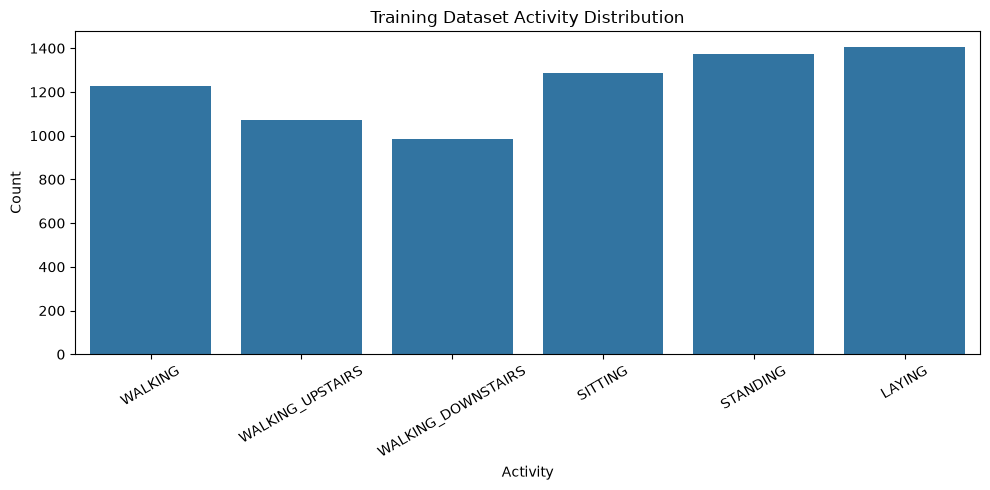

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution_df,
    x="Activity",
    y="Count"
)

plt.title("Training Dataset Activity Distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
activity_mapping = dict(
    zip(
        activity_labels["activity_id"],
        activity_labels["activity"]
    )
)

y_train_names = y_train["activity_id"].map(activity_mapping)

y_train_names.value_counts()

activity_id
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

## Preprocessing

applying standard scaling to training set only

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape :", X_test_scaled.shape)

Training shape: (7352, 561)
Testing shape : (2947, 561)


In [14]:
y_train_encoded = y_train["activity_id"].values - 1
y_test_encoded = y_test["activity_id"].values - 1

print(np.unique(y_train_encoded))

[0 1 2 3 4 5]


Validation split

In [15]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_scaled,
    y_train_encoded,
    test_size=0.10,
    random_state=42,
    stratify=y_train_encoded
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_scaled.shape)

Training: (6616, 561)
Validation: (736, 561)
Test: (2947, 561)


## Feeding data into models now
1. Single layer feedforward network

In [16]:
single_layer_model = Sequential([
    Input(shape=(561,)),
    Dense(6, activation="softmax")
])

single_layer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

single_layer_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │         3,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,372 (13.17 KB)

 Trainable params: 3,372 (13.17 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history_single = single_layer_model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    verbose=1
)

single_test_loss, single_test_accuracy = single_layer_model.evaluate(
    X_test_scaled,
    y_test_encoded,
    verbose=0
)

print("Single-Layer Test Accuracy:", single_test_accuracy)

Epoch 1/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7252 - loss: 0.6846 - val_accuracy: 0.8764 - val_loss: 0.3325
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9271 - loss: 0.2606 - val_accuracy: 0.9361 - val_loss: 0.2125
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9479 - loss: 0.1820 - val_accuracy: 0.9429 - val_loss: 0.1645
Epoch 4/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9599 - loss: 0.1450 - val_accuracy: 0.9538 - val_loss: 0.1378
Epoch 5/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9670 - loss: 0.1229 - val_accuracy: 0.9579 - val_loss: 0.1206
Epoch 6/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9711 - loss: 0.1081 - val_accuracy: 0.9647 - val_loss: 0.1088
Epoch 7/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9743 - loss: 0.0973 - val_accuracy: 0.9688 - val_loss: 0.1000
Epoch 8/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9763 - loss: 0.0892 - val_accuracy: 0.

## Model 2 — Multilayer Feedforward Network

In [18]:
mlp_model = Sequential([
    Input(shape=(561,)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(6, activation="softmax")
])

mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │        71,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,470 (322.15 KB)

 Trainable params: 82,470 (322.15 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history_mlp = mlp_model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    verbose=1
)

mlp_test_loss, mlp_test_accuracy = mlp_model.evaluate(
    X_test_scaled,
    y_test_encoded,
    verbose=0
)

print("MLP Test Accuracy:", mlp_test_accuracy)

Epoch 1/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7027 - loss: 0.7172 - val_accuracy: 0.9198 - val_loss: 0.2143
Epoch 2/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9072 - loss: 0.2456 - val_accuracy: 0.9402 - val_loss: 0.1555
Epoch 3/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9370 - loss: 0.1640 - val_accuracy: 0.9565 - val_loss: 0.1031
Epoch 4/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9479 - loss: 0.1303 - val_accuracy: 0.9647 - val_loss: 0.0920
Epoch 5/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9572 - loss: 0.1076 - val_accuracy: 0.9524 - val_loss: 0.1087
Epoch 6/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9619 - loss: 0.0927 - val_accuracy: 0.9620 - val_loss: 0.0895
Epoch 7/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9690 - loss: 0.0813 - val_accuracy: 0.9620 - val_loss: 0.1000
Epoch 8/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9675 - loss: 0.0791 - val_accuracy: 0.

## Model 3 — PCA

In [20]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_final)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("PCA components:", X_train_pca.shape[1])
print("Variance retained:", pca.explained_variance_ratio_.sum())

Original number of features: 561
PCA components: 101
Variance retained: 0.950122809855472


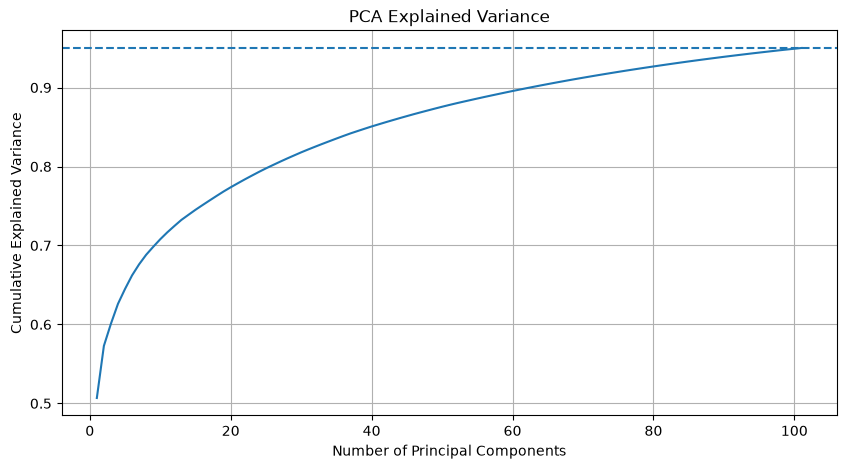

In [21]:
plt.figure(figsize=(10, 5))

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(
    y=0.95,
    linestyle="--"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)

plt.show()

In [22]:
pca_mlp_model = Sequential([
    Input(shape=(X_train_pca.shape[1],)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(6, activation="softmax")
])

pca_mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

pca_mlp_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │        13,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,590 (92.15 KB)

 Trainable params: 23,590 (92.15 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history_pca_mlp = pca_mlp_model.fit(
    X_train_pca,
    y_train_final,
    validation_data=(X_val_pca, y_val),
    epochs=40,
    batch_size=64,
    verbose=1
)

pca_mlp_loss, pca_mlp_accuracy = pca_mlp_model.evaluate(
    X_test_pca,
    y_test_encoded,
    verbose=0
)

print("PCA + MLP Test Accuracy:", pca_mlp_accuracy)

Epoch 1/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6150 - loss: 0.9565 - val_accuracy: 0.8750 - val_loss: 0.3123
Epoch 2/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8632 - loss: 0.3570 - val_accuracy: 0.9443 - val_loss: 0.1393
Epoch 3/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9151 - loss: 0.2191 - val_accuracy: 0.9538 - val_loss: 0.1011
Epoch 4/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9356 - loss: 0.1710 - val_accuracy: 0.9592 - val_loss: 0.0905
Epoch 5/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9468 - loss: 0.1413 - val_accuracy: 0.9647 - val_loss: 0.0812
Epoch 6/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9534 - loss: 0.1259 - val_accuracy: 0.9647 - val_loss: 0.0806
Epoch 7/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9621 - loss: 0.1071 - val_accuracy: 0.9660 - val_loss: 0.0771
Epoch 8/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9643 - loss: 0.0997 - val_accuracy: 0.

## CNN Dataset Preparation
Now we switch from the 561-feature representation to the actual inertial sensor sequences.
The dataset provides 128 readings per window.
samples × 128 timesteps × 9 channels

In [24]:
signal_names = [
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z"
]


def load_inertial_signals(folder):
    signals = []

    for signal in signal_names:
        file_path = os.path.join(
            folder,
            "Inertial Signals",
            f"{signal}_{'train' if 'train' in folder else 'test'}.txt"
        )

        data = np.loadtxt(file_path)

        signals.append(data)

    # Each signal: samples × 128
    # Stack along last dimension:
    # samples × 128 × 9
    X = np.stack(signals, axis=-1)

    return X

In [25]:
train_signal_path = os.path.join(
    DATA_PATH,
    "train"
)

test_signal_path = os.path.join(
    DATA_PATH,
    "test"
)

X_train_seq = load_inertial_signals(train_signal_path)
X_test_seq = load_inertial_signals(test_signal_path)

print("Training sequence shape:", X_train_seq.shape)
print("Testing sequence shape :", X_test_seq.shape)

Training sequence shape: (7352, 128, 9)
Testing sequence shape : (2947, 128, 9)


In [26]:
sequence_scaler = StandardScaler()

X_train_seq_2d = X_train_seq.reshape(-1, 9)
X_test_seq_2d = X_test_seq.reshape(-1, 9)

X_train_seq_scaled = sequence_scaler.fit_transform(
    X_train_seq_2d
).reshape(X_train_seq.shape)

X_test_seq_scaled = sequence_scaler.transform(
    X_test_seq_2d
).reshape(X_test_seq.shape)

print(X_train_seq_scaled.shape)

(7352, 128, 9)


Train/Validation Split for CNN/RNN

In [27]:
X_seq_train, X_seq_val, y_seq_train, y_seq_val = train_test_split(
    X_train_seq_scaled,
    y_train_encoded,
    test_size=0.10,
    random_state=42,
    stratify=y_train_encoded
)

print("Sequence training:", X_seq_train.shape)
print("Sequence validation:", X_seq_val.shape)

Sequence training: (6616, 128, 9)
Sequence validation: (736, 128, 9)


## Model 3 — CNN

In [28]:
cnn_model = Sequential([
    Input(shape=(128, 9)),

    Conv1D(
        filters=64,
        kernel_size=5,
        activation="relu"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu"
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(6, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 58, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 27, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,958 (398.27 KB)

 Trainable params: 101,958 (398.27 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history_cnn = cnn_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=30,
    batch_size=64,
    verbose=1
)

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_seq_scaled,
    y_test_encoded,
    verbose=0
)

print("CNN Test Accuracy:", cnn_test_accuracy)

Epoch 1/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7864 - loss: 0.5692 - val_accuracy: 0.9402 - val_loss: 0.1287
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9389 - loss: 0.1532 - val_accuracy: 0.9429 - val_loss: 0.1081
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9453 - loss: 0.1266 - val_accuracy: 0.9402 - val_loss: 0.1117
Epoch 4/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9518 - loss: 0.1173 - val_accuracy: 0.9457 - val_loss: 0.1002
Epoch 5/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9525 - loss: 0.1139 - val_accuracy: 0.9538 - val_loss: 0.0965
Epoch 6/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9518 - loss: 0.1129 - val_accuracy: 0.9524 - val_loss: 0.0927
Epoch 7/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9547 - loss: 0.1008 - val_accuracy: 0.9552 - val_loss: 0.0913
Epoch 8/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9577 - loss: 0.0965 - val_accu

## Model 4 — RNN / LSTM

In [30]:
lstm_model = Sequential([
    Input(shape=(128, 9)),

    LSTM(
        64,
        return_sequences=True
    ),

    Dropout(0.3),

    LSTM(32),

    Dense(32, activation="relu"),

    Dropout(0.3),

    Dense(6, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128, 64)        │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,614 (127.40 KB)

 Trainable params: 32,614 (127.40 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
history_lstm = lstm_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=30,
    batch_size=64,
    verbose=1
)

lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(
    X_test_seq_scaled,
    y_test_encoded,
    verbose=0
)

print("LSTM Test Accuracy:", lstm_test_accuracy)

Epoch 1/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.6226 - loss: 0.9822 - val_accuracy: 0.8356 - val_loss: 0.4412
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.8572 - loss: 0.4024 - val_accuracy: 0.9416 - val_loss: 0.1903
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.8655 - loss: 0.4007 - val_accuracy: 0.8655 - val_loss: 0.4071
Epoch 4/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9037 - loss: 0.3076 - val_accuracy: 0.9470 - val_loss: 0.1453
Epoch 5/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9376 - loss: 0.2074 - val_accuracy: 0.8573 - val_loss: 0.6195
Epoch 6/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9285 - loss: 0.2185 - val_accuracy: 0.9321 - val_loss: 0.1450
Epoch 7/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9427 - loss: 0.1620 - val_accuracy: 0.9443 - val_loss: 0.1131
Epoch 8/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9495 - loss: 0.1432 - val_accu

In [32]:
results = pd.DataFrame({
    "Model": [
        "Single-Layer Feedforward",
        "Multilayer Feedforward",
        "MLP + PCA",
        "CNN",
        "LSTM/RNN"
    ],
    "Accuracy": [
        single_test_accuracy,
        mlp_test_accuracy,
        pca_mlp_accuracy,
        cnn_test_accuracy,
        lstm_test_accuracy
    ]
})

results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy
0,Multilayer Feedforward,0.954191
1,MLP + PCA,0.948761
2,Single-Layer Feedforward,0.936546
3,CNN,0.933492
4,LSTM/RNN,0.903291


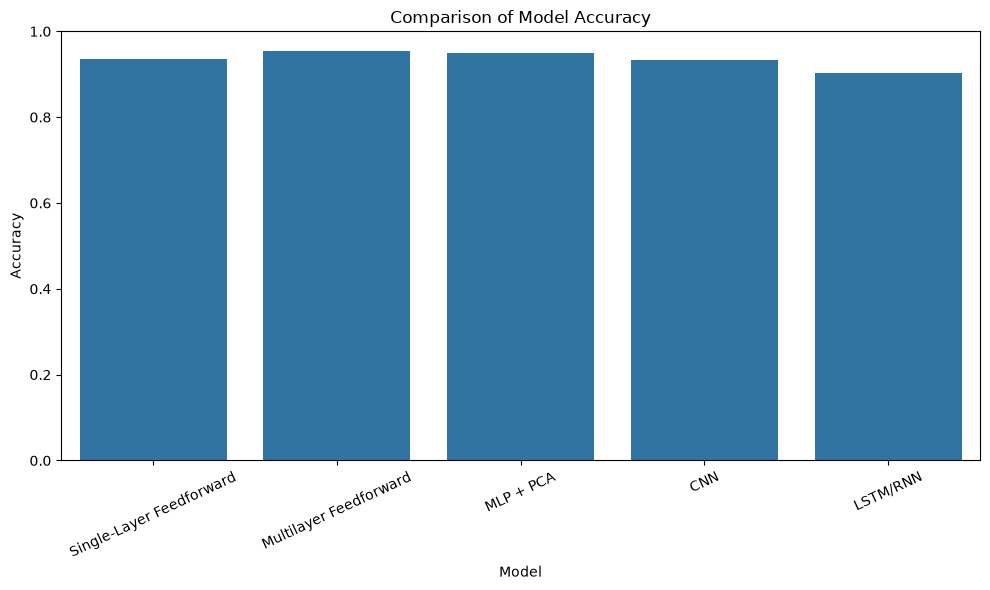

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)

plt.title("Comparison of Model Accuracy")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

## Comprehensive Evaluation

In [34]:
def evaluate_model(model, X_test, y_test, model_name):

    probabilities = model.predict(
        X_test,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted"
    )

    print(f"\n{model_name}")
    print("-" * 40)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [35]:
all_results = []

all_results.append(
    evaluate_model(
        single_layer_model,
        X_test_scaled,
        y_test_encoded,
        "Single-Layer Feedforward"
    )
)

all_results.append(
    evaluate_model(
        mlp_model,
        X_test_scaled,
        y_test_encoded,
        "Multilayer Feedforward"
    )
)

all_results.append(
    evaluate_model(
        pca_mlp_model,
        X_test_pca,
        y_test_encoded,
        "MLP + PCA"
    )
)

all_results.append(
    evaluate_model(
        cnn_model,
        X_test_seq_scaled,
        y_test_encoded,
        "CNN"
    )
)

all_results.append(
    evaluate_model(
        lstm_model,
        X_test_seq_scaled,
        y_test_encoded,
        "LSTM/RNN"
    )
)


Single-Layer Feedforward
----------------------------------------
Accuracy : 0.9365456396335257
Precision: 0.9406981149475903
Recall   : 0.9365456396335257
F1-Score : 0.9367228414762735

Multilayer Feedforward
----------------------------------------
Accuracy : 0.9541907024092298
Precision: 0.9545359867381596
Recall   : 0.9541907024092298
F1-Score : 0.9540712844134918

MLP + PCA
----------------------------------------
Accuracy : 0.9487614523243977
Precision: 0.948957684533909
Recall   : 0.9487614523243977
F1-Score : 0.9486175403245584

CNN
----------------------------------------
Accuracy : 0.9334916864608076
Precision: 0.9367380462550234
Recall   : 0.9334916864608076
F1-Score : 0.9326858334308645

LSTM/RNN
----------------------------------------
Accuracy : 0.9032914828639295
Precision: 0.9064297028996294
Recall   : 0.9032914828639295
F1-Score : 0.9020888680393617


In [36]:
metrics_df = pd.DataFrame(all_results)

metrics_df.sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1-Score
0,Multilayer Feedforward,0.954191,0.954536,0.954191,0.954071
1,MLP + PCA,0.948761,0.948958,0.948761,0.948618
2,Single-Layer Feedforward,0.936546,0.940698,0.936546,0.936723
3,CNN,0.933492,0.936738,0.933492,0.932686
4,LSTM/RNN,0.903291,0.906430,0.903291,0.902089


Identify Best Model

In [37]:
best_model_name = metrics_df.loc[
    metrics_df["F1-Score"].idxmax(),
    "Model"
]

print("Best model:", best_model_name)

Best model: Multilayer Feedforward


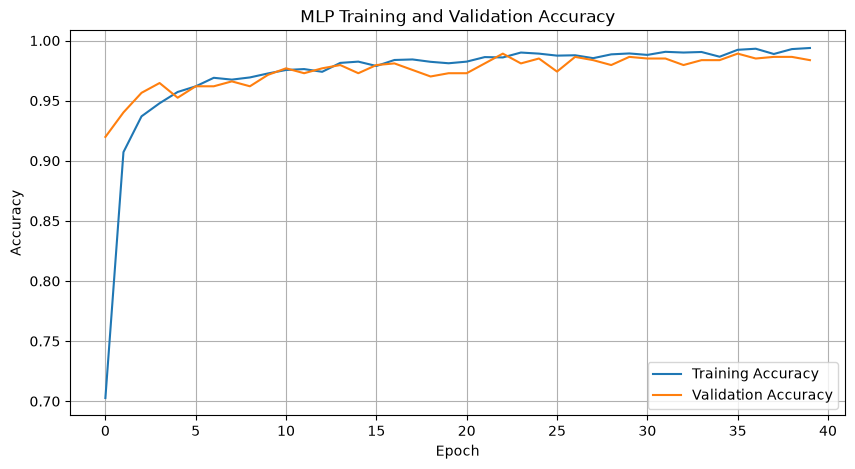

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_mlp.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_mlp.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

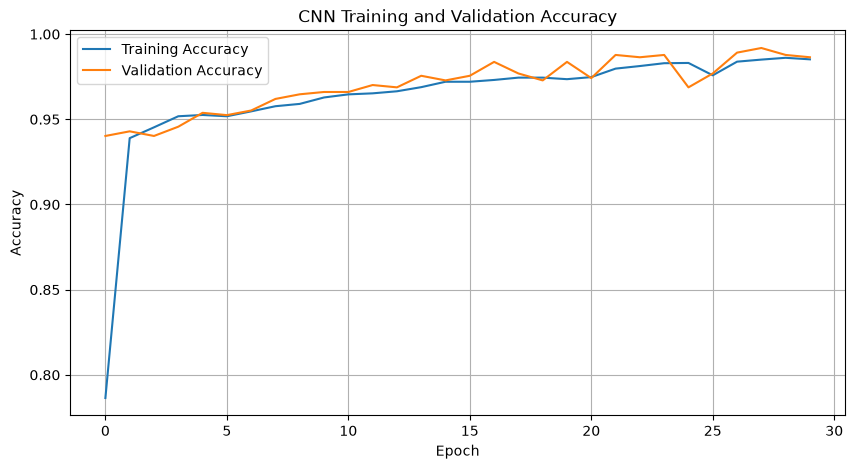

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

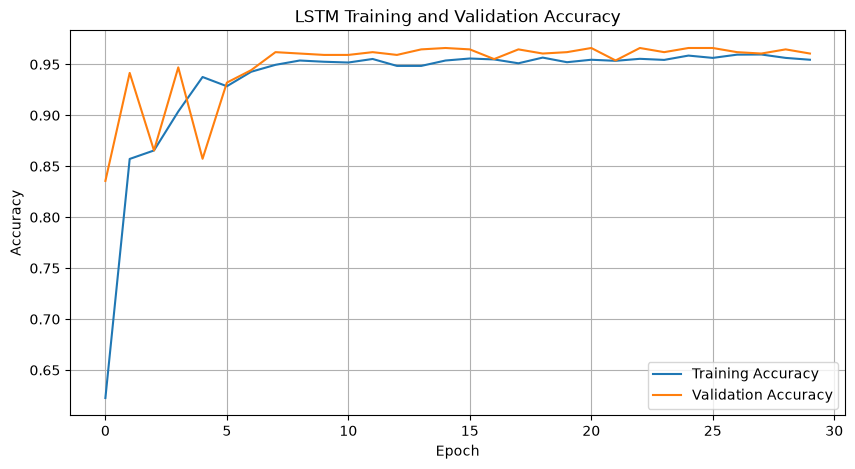

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_lstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [42]:
if best_model_name == "Single-Layer Feedforward":
    best_model = single_layer_model
    best_X = X_test_scaled

elif best_model_name == "Multilayer Feedforward":
    best_model = mlp_model
    best_X = X_test_scaled

elif best_model_name == "MLP + PCA":
    best_model = pca_mlp_model
    best_X = X_test_pca

elif best_model_name == "CNN":
    best_model = cnn_model
    best_X = X_test_seq_scaled

else:
    best_model = lstm_model
    best_X = X_test_seq_scaled


best_predictions = np.argmax(
    best_model.predict(
        best_X,
        verbose=0
    ),
    axis=1
)

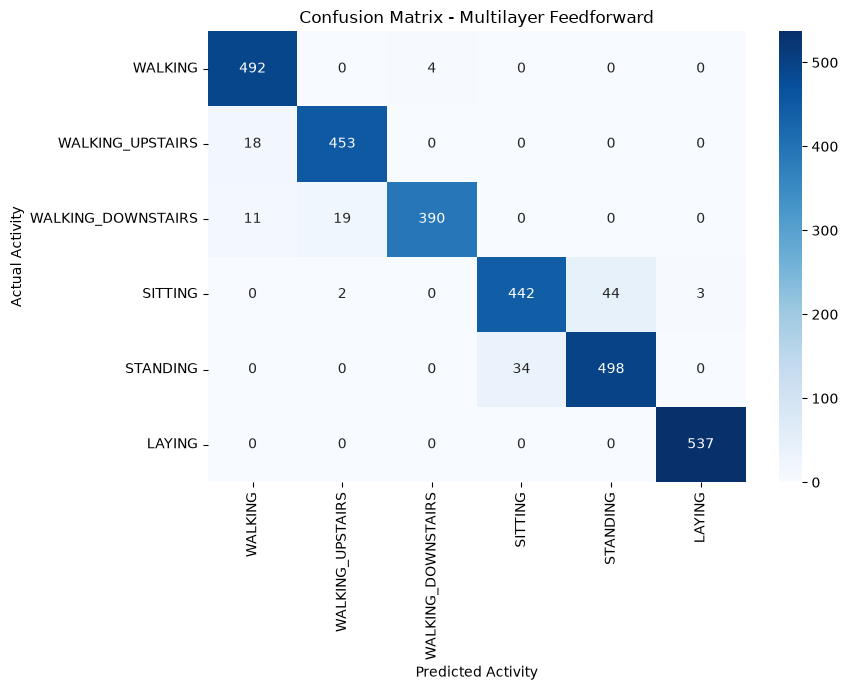

In [43]:
cm = confusion_matrix(
    y_test_encoded,
    best_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_labels["activity"],
    yticklabels=activity_labels["activity"]
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.tight_layout()
plt.show()